Records per cohort year:
cohort_year
2026    200
2019    197
Name: count, dtype: int64


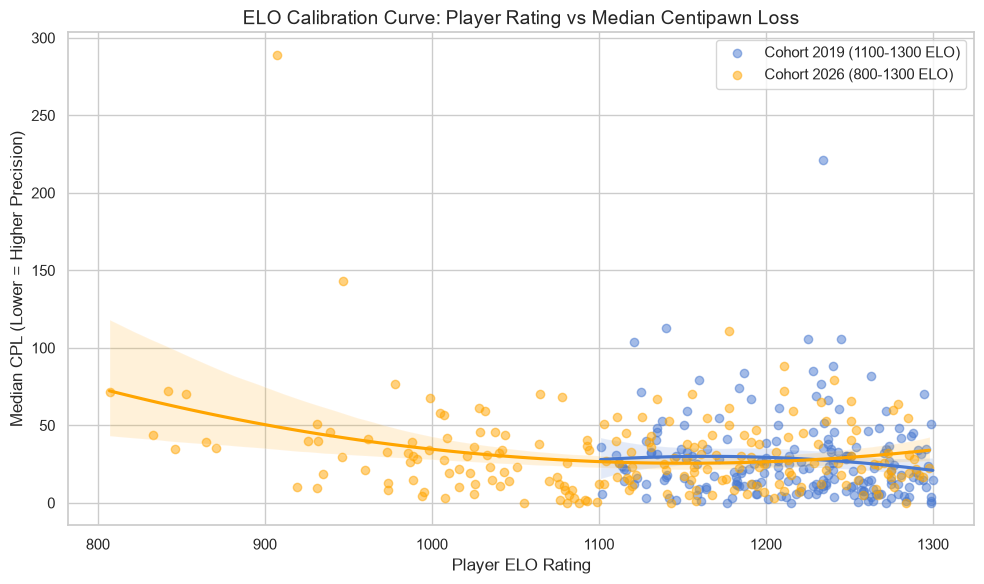

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# To set visual style for research publication
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. To load generated cohort dataset
df = pd.read_csv("chess_acpl_cohorts.csv")

# To display summary of records per cohort
print("Records per cohort year:")
print(df["cohort_year"].value_counts())

# 2. Plot: ELO Calibration Curve (2019 vs 2026)
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df[df["cohort_year"] == 2019],
    x="player_elo",
    y="median_cpl",
    label="Cohort 2019 (1100-1300 ELO)",
    scatter_kws={"alpha": 0.5},
    order=2,
)

sns.regplot(
    data=df[df["cohort_year"] == 2026],
    x="player_elo",
    y="median_cpl",
    label="Cohort 2026 (800-1300 ELO)",
    color="orange",
    scatter_kws={"alpha": 0.5},
    order=2,
)

plt.title(
    "ELO Calibration Curve: Player Rating vs Median Centipawn Loss", fontsize=14
)
plt.xlabel("Player ELO Rating", fontsize=12)
plt.ylabel("Median CPL (Lower = Higher Precision)", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\Administrador\AppData\Local\Temp\ipykernel_1104\2881047552.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Administrador\AppData\Local\Temp\ipykernel_1104\2881047552.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


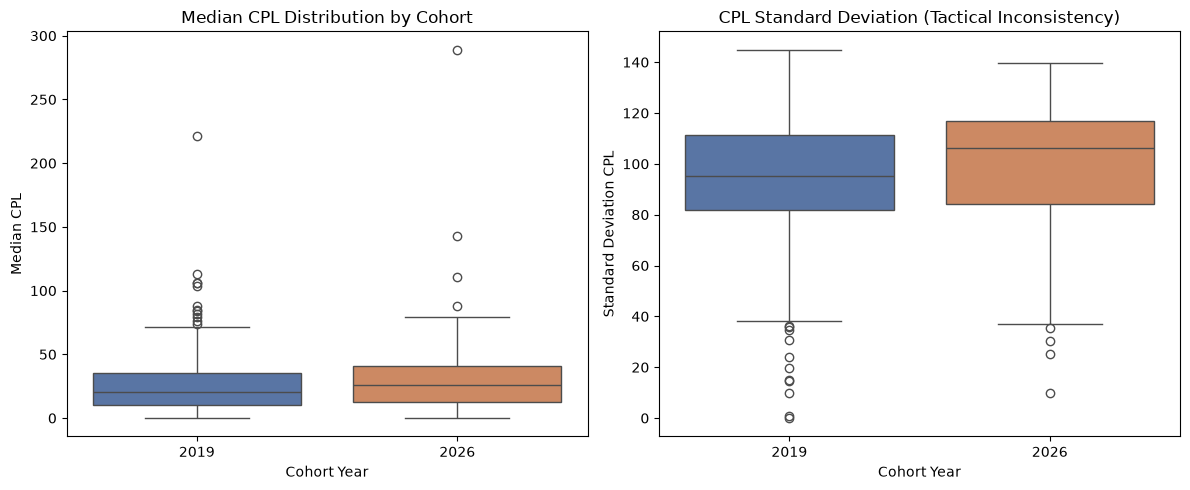

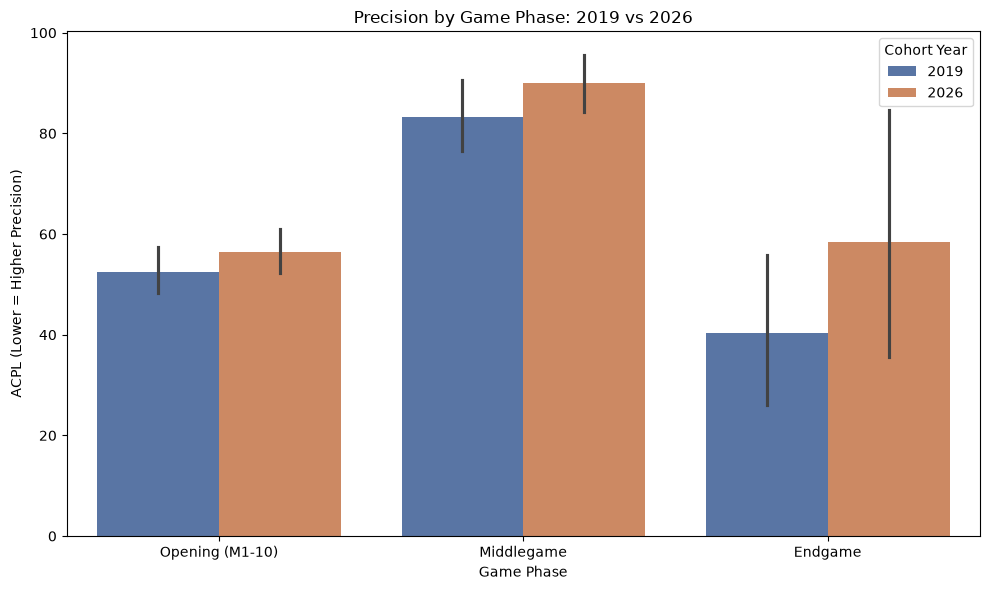

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset
df = pd.read_csv("chess_acpl_cohorts.csv")

# 2. Boxplot: Comparing CPL Variability (std_cpl) between Cohorts
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(
    data=df, x="cohort_year", y="median_cpl", palette=["#4c72b0", "#dd8452"]
)
plt.title("Median CPL Distribution by Cohort")
plt.xlabel("Cohort Year")
plt.ylabel("Median CPL")

plt.subplot(1, 2, 2)
sns.boxplot(
    data=df, x="cohort_year", y="std_cpl", palette=["#4c72b0", "#dd8452"]
)
plt.title("CPL Standard Deviation (Tactical Inconsistency)")
plt.xlabel("Cohort Year")
plt.ylabel("Standard Deviation CPL")

plt.tight_layout()
plt.show()

# 3. Phase Breakdown Comparison (Opening, Middlegame, Endgame)
df_phases = df.melt(
    id_vars=["cohort_year"],
    value_vars=["acpl_opening", "acpl_middlegame", "acpl_endgame"],
    var_name="game_phase",
    value_name="acpl_value",
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_phases,
    x="game_phase",
    y="acpl_value",
    hue="cohort_year",
    palette=["#4c72b0", "#dd8452"],
)
plt.title("Precision by Game Phase: 2019 vs 2026")
plt.xlabel("Game Phase")
plt.ylabel("ACPL (Lower = Higher Precision)")
plt.xticks(
    ticks=[0, 1, 2], labels=["Opening (M1-10)", "Middlegame", "Endgame"]
)
plt.legend(title="Cohort Year")
plt.tight_layout()
plt.show()

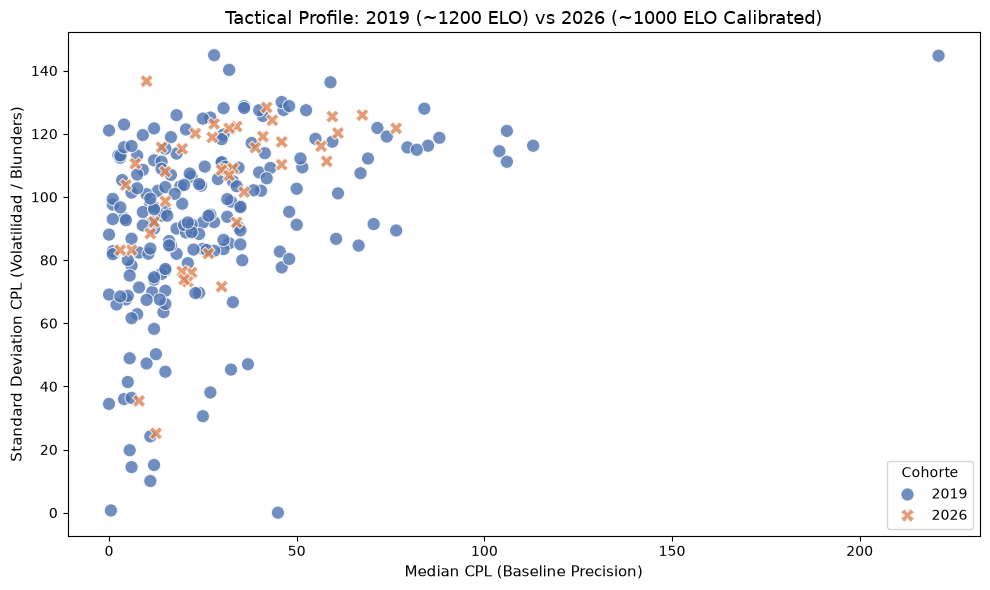

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Cargar el dataset consolidado
df = pd.read_csv("chess_acpl_cohorts.csv")

# 2. Definir muestra pareada por deflación demostrada:
#    Cohorte 2019: 1100-1300 ELO (Baseline)
#    Cohorte 2026: 950-1050 ELO (Nivel equivalente post-deflación)
df_2019_1200 = df[(df["cohort_year"] == 2019) & (df["player_elo"].between(1100, 1300))].copy()
df_2026_1000 = df[(df["cohort_year"] == 2026) & (df["player_elo"].between(950, 1050))].copy()

df_calibrated = pd.concat([df_2019_1200, df_2026_1000])

# 3. Gráfico de dispersión de inconsistencia táctica (STD vs Mediana CPL)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_calibrated,
    x="median_cpl",
    y="std_cpl",
    hue="cohort_year",
    style="cohort_year",
    palette=["#4c72b0", "#dd8452"],
    s=90,
    alpha=0.8
)

plt.title("Tactical Profile: 2019 (~1200 ELO) vs 2026 (~1000 ELO Calibrated)", fontsize=13)
plt.xlabel("Median CPL (Baseline Precision)", fontsize=11)
plt.ylabel("Standard Deviation CPL (Volatilidad / Blunders)", fontsize=11)
plt.legend(title="Cohorte")
plt.tight_layout()
plt.show()